# Eixo 4 — Olhando para frente

## Pergunta de investigação

**O que os profissionais consideram importante para quem está começando na área de tecnologia e quais alertas, tendências ou recomendações desejam compartilhar a partir de sua experiência?**

## Objetivo

Investigar as recomendações dos participantes para quem está começando na área de tecnologia, identificando conhecimentos, competências e experiências considerados importantes, além de alertas, tendências e perspectivas compartilhados a partir de suas vivências profissionais.

## Variáveis analisadas

- Recomendações consideradas importantes para iniciantes;
- Combinações de recomendações selecionadas;
- Alertas, tendências e recomendações registrados em respostas abertas.

## Estratégia de análise

A investigação será organizada em três dimensões:

1. **Recomendações para iniciantes:** identificar quais conhecimentos, competências e experiências foram mais assinalados pelos participantes.
2. **Combinações de recomendações:** observar as combinações de alternativas selecionadas pelos participantes. Os cruzamentos por faixa etária e tempo de atuação foram realizados no Eixo 3.
3. **Alertas e tendências:** analisar qualitativamente as respostas abertas, identificando temas recorrentes, recomendações, percepções e pontos de atenção registrados pelos participantes.

## Cuidados metodológicos

A pergunta sobre recomendações permite até três seleções por participante. Portanto, as frequências representam o número de participantes que assinalaram cada alternativa, e não parcelas exclusivas de um total de respostas.

A pergunta aberta é opcional. As respostas serão analisadas a partir de seu conteúdo original, com classificação temática fundamentada nos relatos. Respostas em branco não serão interpretadas como ausência de opinião.

As análises representam as percepções dos participantes da amostra investigada, sem estabelecer relações causais ou generalizações para o conjunto dos profissionais de tecnologia.

## Relação com o Eixo 3

A pergunta sobre recomendações para quem está começando é analisada em dois eixos, com funções diferentes. No Eixo 3 (Realidade), ela é lida ao lado do cotidiano profissional e da correspondência entre realidade e expectativa, e é cruzada com tempo de atuação e faixa etária. Neste eixo, ela é retomada para compor, junto com as respostas abertas, o conjunto de orientações que os participantes desejam compartilhar.

Por isso, as frequências e combinações das seções 02 e 03 reproduzem os resultados do Eixo 3, sem nova análise. O cruzamento por área de atuação não foi executado em nenhum dos eixos: a área admite múltiplas seleções e vários grupos são pequenos.

 # 01 — Preparação e verificação da base

*Importações, carregamento da fonte original, verificação de integridade e seleção das variáveis.*

In [2]:
# Preparação da base

# Bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Configurações de exibição
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Diretório de execução
diretorio_atual = Path.cwd()

print("Ambiente de análise preparado.")

Ambiente de análise preparado.


In [3]:
# Carregamento da base original

# NOTA SOBRE A VERSÃO DA BASE:
# O arquivo mantém o nome BASELINE_36_RESPOSTAS.csv,
# referente à versão inicial da coleta.
# Seu conteúdo foi atualizado posteriormente e
# corresponde à base consolidada com 54 respostas.

caminho_fonte = (
    diretorio_atual
    / ".."
    / ".."
    / "data"
    / "fonte_original"
    / "Pesquisa — Um Olhar de Quem Está no Campo - BASELINE_36_RESPOSTAS.csv"
).resolve()

if not caminho_fonte.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_fonte}")

df_original = pd.read_csv(caminho_fonte)

print(f"Arquivo: {caminho_fonte.name}")
print(
    f"Dimensões da base: {df_original.shape[0]} linhas × {df_original.shape[1]} colunas"
)

Arquivo: Pesquisa — Um Olhar de Quem Está no Campo - BASELINE_36_RESPOSTAS.csv
Dimensões da base: 54 linhas × 17 colunas


In [4]:
# 01 — Preparação e verificação da base

# 1. Identificação das colunas
colunas_disponiveis = {coluna.strip(): coluna for coluna in df_original.columns}

coluna_recomendacoes = colunas_disponiveis[
    "O que você considera mais importante para quem está começando na sua área?"
]

coluna_alertas = colunas_disponiveis[
    "Há algum alerta, tendência, recomendação ou outro ponto sobre sua experiência que você gostaria de registrar?"
]

coluna_faixa_etaria = colunas_disponiveis["Faixa Etária"]
coluna_tempo_atuacao = colunas_disponiveis["Tempo de atuação na Área"]
coluna_area_atuacao = colunas_disponiveis["Área de Atuação"]


# 2. Seleção das variáveis
colunas_olhando_frente = [
    coluna_recomendacoes,
    coluna_alertas,
    coluna_faixa_etaria,
    coluna_tempo_atuacao,
    coluna_area_atuacao,
]

df_olhando_frente = df_original[colunas_olhando_frente].copy()


# 3. Verificação das dimensões
print("DIMENSÕES DA BASE")

print(
    f"Base original: {df_original.shape[0]} linhas x " f"{df_original.shape[1]} colunas"
)

print(
    f"Base do Eixo 4: {df_olhando_frente.shape[0]} linhas x "
    f"{df_olhando_frente.shape[1]} colunas"
)


# 4. Verificação de valores ausentes
print("\nVALORES AUSENTES — BASE DO EIXO 4")

display(df_olhando_frente.isna().sum().to_frame("respostas_ausentes"))


# 5. Verificação de duplicidade
print("\nVERIFICAÇÃO DE DUPLICIDADE")

print(
    "Linhas integralmente idênticas na base original:", df_original.duplicated().sum()
)

print(
    "Linhas integralmente idênticas na base do Eixo 4:",
    df_olhando_frente.duplicated().sum(),
)

DIMENSÕES DA BASE
Base original: 54 linhas x 17 colunas
Base do Eixo 4: 54 linhas x 5 colunas

VALORES AUSENTES — BASE DO EIXO 4


,respostas_ausentes
O que você considera mais importante para quem está começando na sua área?,0
"Há algum alerta, tendência, recomendação ou outro ponto sobre sua experiência que você gostaria de registrar?",30
Faixa Etária,0
Tempo de atuação na Área,0
Área de Atuação,0



VERIFICAÇÃO DE DUPLICIDADE
Linhas integralmente idênticas na base original: 0
Linhas integralmente idênticas na base do Eixo 4: 0


## 02 — Recomendações para quem está começando

Identificação dos conhecimentos, competências e experiências que os participantes consideram mais importantes para quem está iniciando sua trajetória na área de tecnologia.

A análise considera a frequência de participantes que selecionaram cada recomendação. Como a questão permite até três escolhas, os percentuais representam a proporção de participantes que assinalaram cada alternativa, não categorias exclusivas, podendo ultrapassar 100% quando somados.

**Nota:** esta seção reproduz a distribuição de frequências já apresentada na seção 04 do Eixo 3. Ela é retomada aqui para que as recomendações selecionadas possam ser lidas junto com as respostas abertas, na síntese deste eixo.

In [5]:
# 02 — Frequência das recomendações para iniciantes

# 1. Recuperação das respostas
respostas_recomendacoes = df_olhando_frente[coluna_recomendacoes].dropna().astype(str)

# 2. Separação das múltiplas escolhas
recomendacoes = respostas_recomendacoes.str.split(",").explode().str.strip()

# 3. Contagem das recomendações
frequencia_recomendacoes = (
    recomendacoes.value_counts()
    .rename_axis("recomendacao")
    .reset_index(name="frequencia")
)

# 4. Cálculo do percentual de participantes
total_participantes = respostas_recomendacoes.shape[0]

frequencia_recomendacoes["percentual"] = (
    frequencia_recomendacoes["frequencia"] / total_participantes * 100
).round(1)

# 5. Apresentação dos resultados
print("RECOMENDAÇÕES PARA QUEM ESTÁ COMEÇANDO")
print(f"Participantes com resposta válida: {total_participantes}")
print(
    f"Total de recomendações assinaladas: {frequencia_recomendacoes['frequencia'].sum()}"
)

display(frequencia_recomendacoes)

RECOMENDAÇÕES PARA QUEM ESTÁ COMEÇANDO
Participantes com resposta válida: 54
Total de recomendações assinaladas: 167


,recomendacao,frequencia,percentual
0,Aprender continuamente,38,70.4
1,Buscar experiência prática,30,55.6
2,Desenvolver conhecimento técnico,27,50.0
3,Desenvolver habilidades comportamentais,25,46.3
4,Construir uma rede de contatos,18,33.3
5,Acompanhar tendências do mercado,16,29.6
6,Conhecer diferentes áreas da tecnologia,11,20.4
7,visão para a resolução de problemas,1,1.9
8,Visão de produto e conceitos sólidos de arquit...,1,1.9


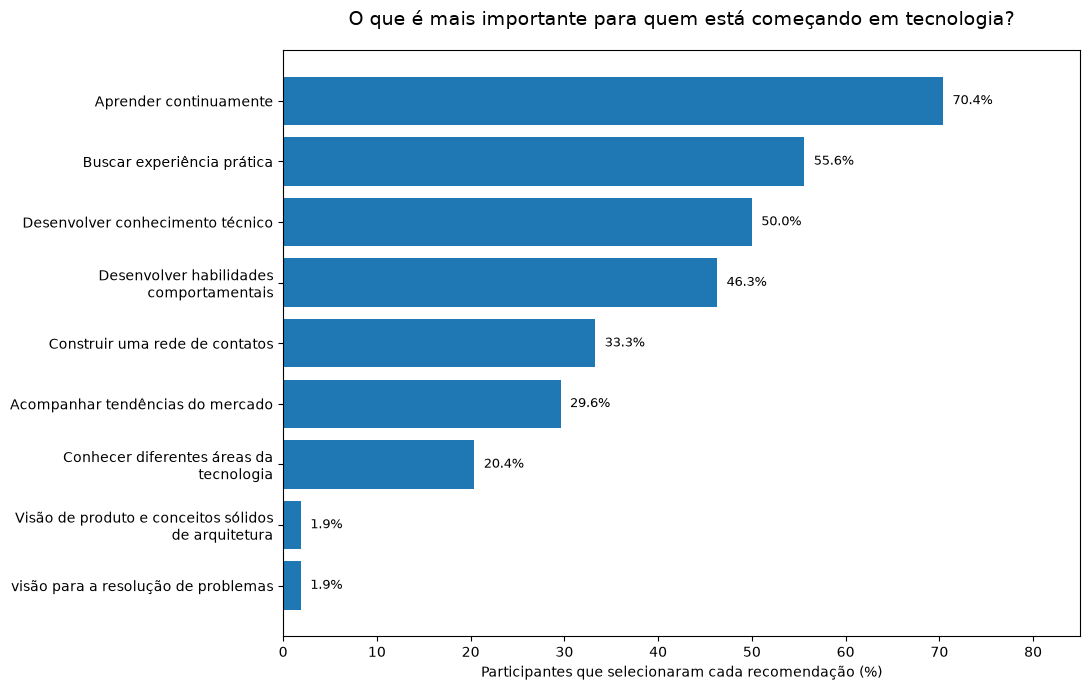

In [6]:
# 03 — Visualização da frequência das recomendações

import matplotlib.pyplot as plt
import textwrap

dados_grafico = frequencia_recomendacoes.sort_values(
    by="percentual", ascending=True
).copy()

# Quebra de linhas para facilitar a leitura dos rótulos
rotulos = [
    "\n".join(textwrap.wrap(texto, width=38)) for texto in dados_grafico["recomendacao"]
]

plt.figure(figsize=(11, 7))

barras = plt.barh(rotulos, dados_grafico["percentual"])

plt.title(
    "O que é mais importante para quem está começando em tecnologia?",
    fontsize=14,
    pad=18,
)

plt.xlabel("Participantes que selecionaram cada recomendação (%)")
plt.ylabel("")

plt.xlim(0, 85)

for barra, percentual in zip(barras, dados_grafico["percentual"]):
    plt.text(
        barra.get_width() + 1,
        barra.get_y() + barra.get_height() / 2,
        f"{percentual:.1f}%",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

### Leitura analítica

A aprendizagem contínua aparece como a recomendação mais frequente, assinalada por 38 participantes (70,4%). Em seguida, destacam-se a busca por experiência prática, mencionada por 30 participantes (55,6%), e o desenvolvimento de conhecimento técnico, indicado por 27 (50,0%).

As habilidades comportamentais também ocupam posição expressiva, com 25 indicações (46,3%). A construção de uma rede de contatos foi selecionada por 18 participantes (33,3%), enquanto acompanhar as tendências do mercado apareceu em 16 respostas (29,6%).

Conhecer diferentes áreas da tecnologia foi mencionado por 11 participantes (20,4%).

Além das alternativas predefinidas, duas respostas abertas acrescentaram perspectivas específicas: visão de produto e conceitos sólidos de arquitetura; e visão para a resolução de problemas. Cada uma foi registrada por um participante (1,9%).

Em conjunto, as respostas apontam para uma visão de preparação profissional que combina atualização constante, experiência prática, conhecimento técnico e competências comportamentais. A aprendizagem contínua se destaca, mas não aparece isoladamente: as demais recomendações mostram que os participantes também valorizam a capacidade de aplicar conhecimentos, desenvolver relações profissionais e compreender o contexto mais amplo da tecnologia.

**Nota metodológica:** a questão permitia até três escolhas por participante. Os percentuais representam a proporção dos 54 respondentes que selecionou cada recomendação. As duas respostas abertas foram mantidas separadas das alternativas predefinidas.

## 03 — Combinações de recomendações

Identificação das combinações de conhecimentos, competências e experiências selecionadas pelos participantes como importantes para quem está começando na área de tecnologia.

A análise busca observar quais recomendações aparecem conjuntamente nas respostas, identificando possíveis padrões de escolha e a diversidade de perspectivas sobre a preparação profissional.

Como o questionário permitia até três opções, as combinações serão examinadas considerando as escolhas registradas por cada participante. As respostas abertas serão preservadas e interpretadas separadamente das alternativas predefinidas, quando necessário.

**Nota:** as combinações apresentadas aqui são as mesmas já analisadas no Eixo 3. Os resultados são retomados sem nova análise.

In [7]:
from IPython.display import display
import pandas as pd

# ============================================================
# COMBINAÇÕES DE RECOMENDAÇÕES — APRESENTAÇÃO FINAL
# ============================================================

# Cópia da tabela já calculada na etapa anterior
tabela_combinacoes = frequencia_combinacoes.copy()

# Identificação das colunas, sem depender de maiúsculas/minúsculas
colunas = {
    str(coluna).strip().casefold(): coluna for coluna in tabela_combinacoes.columns
}

coluna_combinacao = next(coluna for nome, coluna in colunas.items() if "combin" in nome)

coluna_participantes = next(
    coluna for nome, coluna in colunas.items() if "particip" in nome
)

coluna_percentual = next(
    coluna for nome, coluna in colunas.items() if "percent" in nome
)

# Seleção e padronização das colunas exibidas
tabela_combinacoes = tabela_combinacoes[
    [coluna_combinacao, coluna_participantes, coluna_percentual]
].copy()

tabela_combinacoes.columns = [
    "Combinação de recomendações",
    "Participantes",
    "Percentual",
]

# Ordenação: combinações com maior número de participantes primeiro
tabela_combinacoes = tabela_combinacoes.sort_values(
    by=["Participantes", "Combinação de recomendações"], ascending=[False, True]
).reset_index(drop=True)


# Formatação dos percentuais
def formatar_percentual(valor):
    valor = float(valor)

    if valor <= 1:
        valor *= 100

    return f"{valor:.1f}%"


tabela_combinacoes["Percentual"] = tabela_combinacoes["Percentual"].apply(
    formatar_percentual
)

# Indicadores de conferência
total_participantes = int(tabela_combinacoes["Participantes"].sum())
total_combinacoes = len(tabela_combinacoes)

print("=" * 65)
print("COMBINAÇÕES DE RECOMENDAÇÕES")
print("=" * 65)
print(f"Participantes contabilizados: {total_participantes}")
print(f"Combinações distintas identificadas: {total_combinacoes}")

# Exibição única, com quebra automática de linha
estilo_tabela = tabela_combinacoes.style.hide(axis="index").set_table_styles(
    [
        {
            "selector": "table",
            "props": [
                ("width", "100%"),
                ("table-layout", "fixed"),
                ("border-collapse", "collapse"),
            ],
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "left"),
                ("padding", "10px"),
                ("white-space", "normal"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("padding", "10px"),
                ("white-space", "normal"),
                ("overflow-wrap", "break-word"),
                ("word-wrap", "break-word"),
                ("vertical-align", "top"),
            ],
        },
        {
            "selector": "th.col0, td.col0",
            "props": [("width", "68%"), ("text-align", "left")],
        },
        {
            "selector": "th.col1, td.col1",
            "props": [("width", "16%"), ("text-align", "center")],
        },
        {
            "selector": "th.col2, td.col2",
            "props": [("width", "16%"), ("text-align", "center")],
        },
    ]
)

display(estilo_tabela)

NameError: name 'frequencia_combinacoes' is not defined

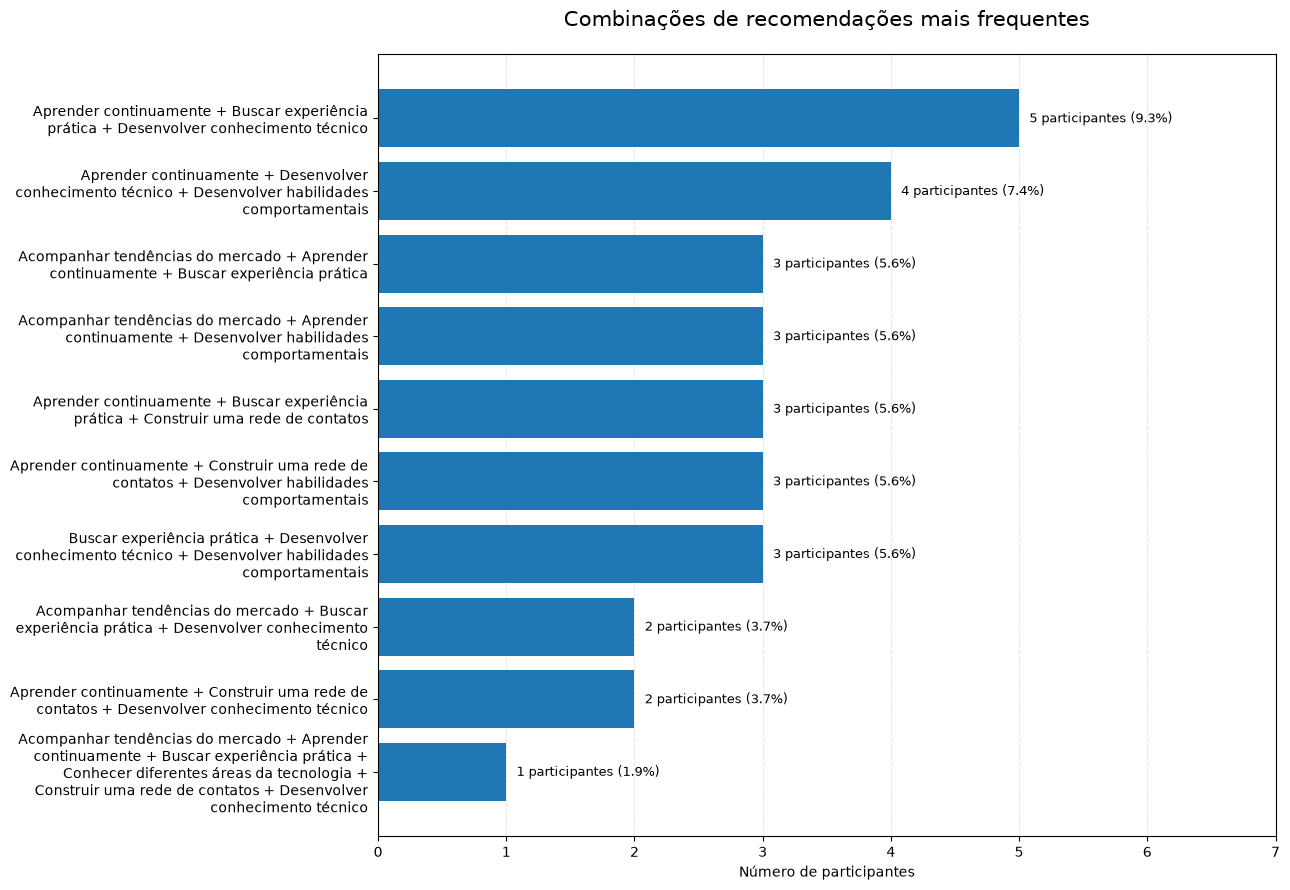

In [ ]:
import matplotlib.pyplot as plt
import textwrap

# Selecionar as 10 combinações mais frequentes
dados_grafico = (
    tabela_combinacoes.sort_values("Participantes", ascending=False).head(10).copy()
)

# Preparar os rótulos com quebra de linha
rotulos = [
    textwrap.fill(texto, width=48)
    for texto in dados_grafico["Combinação de recomendações"]
]

valores = dados_grafico["Participantes"].astype(int)

# Recuperar os percentuais numéricos
percentuais = (
    dados_grafico["Percentual"]
    .str.replace("%", "", regex=False)
    .str.replace(",", ".", regex=False)
    .astype(float)
)

# Criar gráfico
fig, ax = plt.subplots(figsize=(13, 9))

barras = ax.barh(rotulos, valores)

# Inverter para apresentar a maior frequência no topo
ax.invert_yaxis()

# Identificar participantes e percentuais
for barra, quantidade, percentual in zip(barras, valores, percentuais):
    ax.text(
        barra.get_width() + 0.08,
        barra.get_y() + barra.get_height() / 2,
        f"{quantidade} participantes ({percentual:.1f}%)",
        va="center",
        fontsize=9,
    )

# Títulos e organização visual
ax.set_title("Combinações de recomendações mais frequentes", fontsize=15, pad=20)

ax.set_xlabel("Número de participantes")
ax.set_ylabel("")

ax.set_xlim(0, valores.max() + 2)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Leitura analítica

A distribuição das combinações evidencia a diversidade de percepções dos participantes sobre os conhecimentos, as experiências e as competências considerados importantes para quem está começando na área de tecnologia.

As **10 combinações mais frequentes** reúnem 29 participantes (53,7% da amostra). As duas primeiras aparecem com maior recorrência:

- **Aprender continuamente + Buscar experiência prática + Desenvolver conhecimento técnico:** 5 participantes (9,3%).
- **Aprender continuamente + Desenvolver conhecimento técnico + Desenvolver habilidades comportamentais:** 4 participantes (7,4%).

As demais combinações entre as dez mais frequentes foram selecionadas por grupos de três ou dois participantes, com uma ocorrência de apenas um participante entre elas.

Quando observamos o conjunto completo, identificamos **35 combinações distintas**. As outras 25 combinações, correspondentes a 25 participantes (46,3%), aparecem individualmente, indicando uma ampla variedade de arranjos nas respostas.

Esse resultado sugere que, embora alguns conjuntos de recomendações se repitam, não existe uma combinação predominante entre os participantes. As respostas articulam diferentes dimensões da formação profissional, incluindo atualização contínua, experiência prática, conhecimento técnico, habilidades comportamentais, networking e acompanhamento das tendências do mercado.

A diversidade observada reforça que as recomendações para ingressar ou se desenvolver na tecnologia não se restringem a um único conjunto de competências. Os participantes apresentam diferentes percepções sobre os caminhos e recursos que podem contribuir para a construção de uma trajetória profissional na área.

**Nota metodológica:** cada combinação representa o conjunto de alternativas selecionadas por um participante. O gráfico destaca as dez combinações mais frequentes, enquanto a tabela apresenta as 35 identificadas. Os resultados descrevem a distribuição das escolhas na amostra investigada e não estabelecem uma hierarquia de importância entre as recomendações.

# 04 — Alertas, tendências e recomendações

Este bloco analisa as percepções espontâneas dos participantes sobre suas experiências profissionais, reunindo alertas, tendências, recomendações e pontos de atenção relacionados ao trabalho na área de tecnologia.

A análise busca identificar os principais temas presentes nos relatos e compreender quais reflexões os profissionais consideram importantes compartilhar a partir de sua vivência no setor.

In [ ]:
import pandas as pd
import re
from IPython.display import display

# ==========================================================
# 04.1 — INSPEÇÃO DAS RESPOSTAS ABERTAS
# ==========================================================

# Identificação da coluna da segunda pergunta
coluna_resposta = next(
    coluna for coluna in df_original.columns if "Há algum alerta, tendência" in coluna
)

# Seleção das respostas preenchidas
respostas_abertas = df_original[[coluna_resposta]].dropna().copy()

# Remoção de espaços excedentes
respostas_abertas[coluna_resposta] = (
    respostas_abertas[coluna_resposta].astype(str).str.strip()
)

respostas_abertas = respostas_abertas[respostas_abertas[coluna_resposta] != ""].copy()

# Identificação sequencial dos relatos
respostas_abertas = respostas_abertas.reset_index()

respostas_abertas = respostas_abertas.rename(
    columns={"index": "Índice original", coluna_resposta: "Resposta original"}
)

respostas_abertas["Participante"] = respostas_abertas.index + 1


# Ocultação de possíveis endereços de e-mail
def anonimizar_email(texto):
    return re.sub(r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b", "[e-mail ocultado]", texto)


respostas_abertas["Resposta para análise"] = respostas_abertas[
    "Resposta original"
].apply(anonimizar_email)

# Apresentação
print("=" * 65)
print("INSPEÇÃO DAS RESPOSTAS ABERTAS")
print("=" * 65)

print(f"Participantes na base: {len(df_original)}")
print(f"Respostas preenchidas: {len(respostas_abertas)}")

display(respostas_abertas[["Participante", "Resposta para análise"]])

INSPEÇÃO DAS RESPOSTAS ABERTAS
Participantes na base: 54
Respostas preenchidas: 24


,Participante,Resposta para análise
0,1,"Muito cuidado com ""inovações, modismos e novidades""...procure entender e estudar o que se mostra mais perene."
1,2,"Como trabalho na área de suporte, para quem está iniciando agora, sempre recomendo identificar e conhecer as ferramentas utilizadas no dia a dia. Além disso, é fundamental documentar os chamados com todas as informações relevantes sobre a atividade realizada."
2,3,observar as oportunidades sem precisar puxar saco
3,4,"Recomendação: Para quem quer entrar na área sabendo onde pisa, quais ferramentas usar, foco na lógica de programação e nas matérias teóricas dos cursos, assim a prática vai ser bem mais suave como uma pessoa que leu o manual de instruções de uma nova máquina antes de manuseala, às vezes, começar com calma é a chave. Abraços e espero ter contribuido pra pesquisa."
4,5,"Não existem atalhos. Tudo é difícil e dá trabalho. Tem que ter paciência e foco. Porém, a dificuldade não é a mesma sempre. No início, até solidificar as bases, é mais difícil, depois disso, a curva de aprendizado cresce bem mais rápido."
5,6,Em breve não haverão mais telas e sim entidades inteligentes que suportarão a humanidade... ... .
6,7,"Não saia correndo estudando tudo, nem lendo os livros clássicos. Estude os fundamentos e fale com alguém que está na área para decidir e ter dicas de por onde começar."
7,8,O mercado tecnológico é uma espiral de inovação. Manter-se atualizado deve ser uma constante.
8,9,O recado fica é estar em constante aprendizado e ter a mente aberta para entender o que o mercado precisa.
9,10,[e-mail ocultado]


In [ ]:
# ==========================================================
# 04.2 — CODIFICAÇÃO TEMÁTICA DAS RESPOSTAS ABERTAS
# ==========================================================

classificacoes = [
    {
        "Participante": 1,
        "Tema principal": "Discernimento diante das inovações",
        "Temas secundários": "Fundamentos perenes; avaliação crítica de tendências",
        "Justificativa": "Recomenda cautela diante de modismos e prioriza o estudo do que permanece relevante.",
        "Status": "Analisável",
    },
    {
        "Participante": 2,
        "Tema principal": "Práticas e organização do trabalho",
        "Temas secundários": "Conhecimento de ferramentas; documentação técnica",
        "Justificativa": "Destaca o domínio das ferramentas cotidianas e o registro adequado das atividades de suporte.",
        "Status": "Analisável",
    },
    {
        "Participante": 3,
        "Tema principal": "Oportunidades e relações profissionais",
        "Temas secundários": "Autonomia; posicionamento profissional",
        "Justificativa": "Recomenda observar oportunidades sem recorrer à bajulação como estratégia profissional.",
        "Status": "Analisável",
    },
    {
        "Participante": 4,
        "Tema principal": "Fundamentos e formação técnica",
        "Temas secundários": "Lógica de programação; conhecimento de ferramentas; aprendizagem gradual",
        "Justificativa": "Defende conhecer os fundamentos e as ferramentas antes de avançar para a prática.",
        "Status": "Analisável",
    },
    {
        "Participante": 5,
        "Tema principal": "Persistência e ritmo de aprendizagem",
        "Temas secundários": "Paciência; foco; consolidação de fundamentos",
        "Justificativa": "Relaciona o desenvolvimento profissional à dedicação e à compreensão de que a aprendizagem ocorre em etapas.",
        "Status": "Analisável",
    },
    {
        "Participante": 6,
        "Tema principal": "Transformações futuras da tecnologia",
        "Temas secundários": "Inteligência artificial; entidades inteligentes",
        "Justificativa": "Apresenta uma perspectiva sobre possíveis transformações na interação entre pessoas e tecnologia.",
        "Status": "Analisável",
    },
    {
        "Participante": 7,
        "Tema principal": "Fundamentos e orientação profissional",
        "Temas secundários": "Aprendizagem direcionada; troca com profissionais experientes",
        "Justificativa": "Recomenda evitar estudos dispersos, priorizar fundamentos e buscar orientação de quem já atua na área.",
        "Status": "Analisável",
    },
    {
        "Participante": 8,
        "Tema principal": "Atualização e aprendizagem contínua",
        "Temas secundários": "Inovação; transformações do mercado",
        "Justificativa": "Caracteriza o setor como um ambiente de inovação constante e destaca a necessidade de atualização.",
        "Status": "Analisável",
    },
    {
        "Participante": 9,
        "Tema principal": "Atualização e aprendizagem contínua",
        "Temas secundários": "Abertura à mudança; compreensão das necessidades do mercado",
        "Justificativa": "Associa a aprendizagem contínua à capacidade de compreender as demandas do mercado.",
        "Status": "Analisável",
    },
    {
        "Participante": 10,
        "Tema principal": "Não classificável",
        "Temas secundários": "Informação de contato",
        "Justificativa": "O registro contém somente um endereço de e-mail, sem manifestação relacionada à pergunta.",
        "Status": "Excluir da análise temática",
    },
    {
        "Participante": 11,
        "Tema principal": "Inteligência artificial",
        "Temas secundários": "Aprendizagem contínua; incorporação da IA à rotina",
        "Justificativa": "Recomenda aprender e trabalhar com inteligência artificial diariamente.",
        "Status": "Analisável",
    },
    {
        "Participante": 12,
        "Tema principal": "Aprendizagem contínua",
        "Temas secundários": "Projetos práticos; curiosidade; colaboração; resolução de problemas; portfólio",
        "Justificativa": "Articula atualização profissional, experiência prática e construção de projetos voltados a problemas reais.",
        "Status": "Analisável",
    },
    {
        "Participante": 13,
        "Tema principal": "Comunicação profissional",
        "Temas secundários": "Clareza; adequação ao público; alinhamento de expectativas",
        "Justificativa": "Destaca a comunicação objetiva e o alinhamento entre profissionais e públicos com diferentes níveis de conhecimento.",
        "Status": "Analisável",
    },
    {
        "Participante": 14,
        "Tema principal": "Resolução de problemas",
        "Temas secundários": "Aplicação de ferramentas; identificação de problemas",
        "Justificativa": "Enfatiza a capacidade de aplicar ferramentas tecnológicas para solucionar problemas ainda não resolvidos.",
        "Status": "Analisável",
    },
    {
        "Participante": 15,
        "Tema principal": "Inteligência artificial",
        "Temas secundários": "Domínio tecnológico; relevância profissional",
        "Justificativa": "Defende o aprofundamento em inteligência artificial como fator de relevância no mercado de trabalho.",
        "Status": "Analisável",
    },
    {
        "Participante": 16,
        "Tema principal": "Experiência prática",
        "Temas secundários": "Aprendizagem pela prática",
        "Justificativa": "Expressa preferência pela aplicação prática em relação à aprendizagem exclusivamente teórica.",
        "Status": "Analisável",
    },
    {
        "Participante": 17,
        "Tema principal": "Inteligência artificial e supervisão humana",
        "Temas secundários": "Produtividade; revisão de código; qualidade; refatoração; desempenho",
        "Justificativa": "Relata mudanças no desenvolvimento de software com IA e destaca a responsabilidade humana pela revisão e melhoria do código.",
        "Status": "Analisável",
    },
    {
        "Participante": 18,
        "Tema principal": "Uso crítico da inteligência artificial",
        "Temas secundários": "Autonomia intelectual; validação; aprendizagem; questionamento",
        "Justificativa": "Recomenda não delegar o pensamento à IA e utilizar o tempo economizado para estudar, questionar e avaliar as soluções geradas.",
        "Status": "Analisável",
    },
    {
        "Participante": 19,
        "Tema principal": "Acompanhamento das tendências em IA",
        "Temas secundários": "Informação; atualização profissional",
        "Justificativa": "Recomenda acompanhar conteúdos informativos sobre inteligência artificial por meio de podcasts, artigos e notícias.",
        "Status": "Analisável",
    },
    {
        "Participante": 20,
        "Tema principal": "Persistência e motivação",
        "Temas secundários": "Resiliência; continuidade",
        "Justificativa": "Apresenta uma mensagem breve de incentivo à continuidade da trajetória profissional.",
        "Status": "Analisável",
    },
    {
        "Participante": 21,
        "Tema principal": "Colaboração e troca de experiências",
        "Temas secundários": "Compartilhamento de conhecimentos; diversidade de soluções",
        "Justificativa": "Destaca a troca entre profissionais como meio de conhecer diferentes caminhos para solucionar problemas.",
        "Status": "Analisável",
    },
    {
        "Participante": 22,
        "Tema principal": "Comunidades e eventos profissionais",
        "Temas secundários": "Troca de experiências; geração de ideias",
        "Justificativa": "Relaciona comunidades e eventos à geração de ideias, mas o relato está incompleto e não permite ampliar a interpretação.",
        "Status": "Analisável com ressalva",
    },
    {
        "Participante": 23,
        "Tema principal": "Impacto social da tecnologia",
        "Temas secundários": "Interesse coletivo; soluções para a população; responsabilidade social",
        "Justificativa": "Defende que o desenvolvimento tecnológico considere as necessidades da população, para além da busca por lucro.",
        "Status": "Analisável",
    },
    {
        "Participante": 24,
        "Tema principal": "Fundamentos e desenvolvimento profissional",
        "Temas secundários": "Aprendizagem progressiva; especialização; networking; LinkedIn",
        "Justificativa": "Recomenda consolidar os fundamentos antes de avançar para temas complexos e manter uma rede profissional ativa.",
        "Status": "Analisável",
    },
]

df_codificacao = pd.DataFrame(classificacoes)

# Conferência da quantidade e dos registros
print("CODIFICAÇÃO TEMÁTICA")
print("=" * 60)

print(f"Registros classificados: {len(df_codificacao)}")
print(
    "Respostas analisáveis:",
    (df_codificacao["Status"] != "Excluir da análise temática").sum(),
)
print(
    "Registros excluídos:",
    (df_codificacao["Status"] == "Excluir da análise temática").sum(),
)
print(
    "Registros com ressalva:",
    (df_codificacao["Status"] == "Analisável com ressalva").sum(),
)

display(df_codificacao)

CODIFICAÇÃO TEMÁTICA
Registros classificados: 24
Respostas analisáveis: 23
Registros excluídos: 1
Registros com ressalva: 1


,Participante,Tema principal,Temas secundários,Justificativa,Status
0,1,Discernimento diante das inovações,Fundamentos perenes; avaliação crítica de tendências,Recomenda cautela diante de modismos e prioriza o estudo do que permanece relevante.,Analisável
1,2,Práticas e organização do trabalho,Conhecimento de ferramentas; documentação técnica,Destaca o domínio das ferramentas cotidianas e o registro adequado das atividades de suporte.,Analisável
2,3,Oportunidades e relações profissionais,Autonomia; posicionamento profissional,Recomenda observar oportunidades sem recorrer à bajulação como estratégia profissional.,Analisável
3,4,Fundamentos e formação técnica,Lógica de programação; conhecimento de ferramentas; aprendizagem gradual,Defende conhecer os fundamentos e as ferramentas antes de avançar para a prática.,Analisável
4,5,Persistência e ritmo de aprendizagem,Paciência; foco; consolidação de fundamentos,Relaciona o desenvolvimento profissional à dedicação e à compreensão de que a aprendizagem ocorre em etapas.,Analisável
5,6,Transformações futuras da tecnologia,Inteligência artificial; entidades inteligentes,Apresenta uma perspectiva sobre possíveis transformações na interação entre pessoas e tecnologia.,Analisável
6,7,Fundamentos e orientação profissional,Aprendizagem direcionada; troca com profissionais experientes,"Recomenda evitar estudos dispersos, priorizar fundamentos e buscar orientação de quem já atua na área.",Analisável
7,8,Atualização e aprendizagem contínua,Inovação; transformações do mercado,Caracteriza o setor como um ambiente de inovação constante e destaca a necessidade de atualização.,Analisável
8,9,Atualização e aprendizagem contínua,Abertura à mudança; compreensão das necessidades do mercado,Associa a aprendizagem contínua à capacidade de compreender as demandas do mercado.,Analisável
9,10,Não classificável,Informação de contato,"O registro contém somente um endereço de e-mail, sem manifestação relacionada à pergunta.",Excluir da análise temática


In [ ]:
# ============================================================
# 04.3 — FREQUÊNCIA DOS TEMAS PRINCIPAIS
# ============================================================

# Considerar respostas analisáveis, incluindo a resposta com ressalva
df_temas = df_codificacao[
    df_codificacao["Status"].isin(["Analisável", "Analisável com ressalva"])
].copy()

# Contagem e percentual por tema principal
frequencia_temas = df_temas["Tema principal"].value_counts().reset_index()

frequencia_temas.columns = ["Tema principal", "Participantes"]

frequencia_temas["Percentual"] = (
    frequencia_temas["Participantes"] / len(df_temas) * 100
).round(1)

# Apresentação
print("FREQUÊNCIA DOS TEMAS PRINCIPAIS")
print("=" * 55)
print(f"Respostas consideradas: {len(df_temas)}")
print(f"Temas identificados: {len(frequencia_temas)}")

display(frequencia_temas)

FREQUÊNCIA DOS TEMAS PRINCIPAIS
Respostas consideradas: 23
Temas identificados: 21


,Tema principal,Participantes,Percentual
0,Atualização e aprendizagem contínua,2,8.7
1,Inteligência artificial,2,8.7
2,Discernimento diante das inovações,1,4.3
3,Práticas e organização do trabalho,1,4.3
4,Oportunidades e relações profissionais,1,4.3
5,Fundamentos e formação técnica,1,4.3
6,Persistência e ritmo de aprendizagem,1,4.3
7,Transformações futuras da tecnologia,1,4.3
8,Fundamentos e orientação profissional,1,4.3
9,Aprendizagem contínua,1,4.3


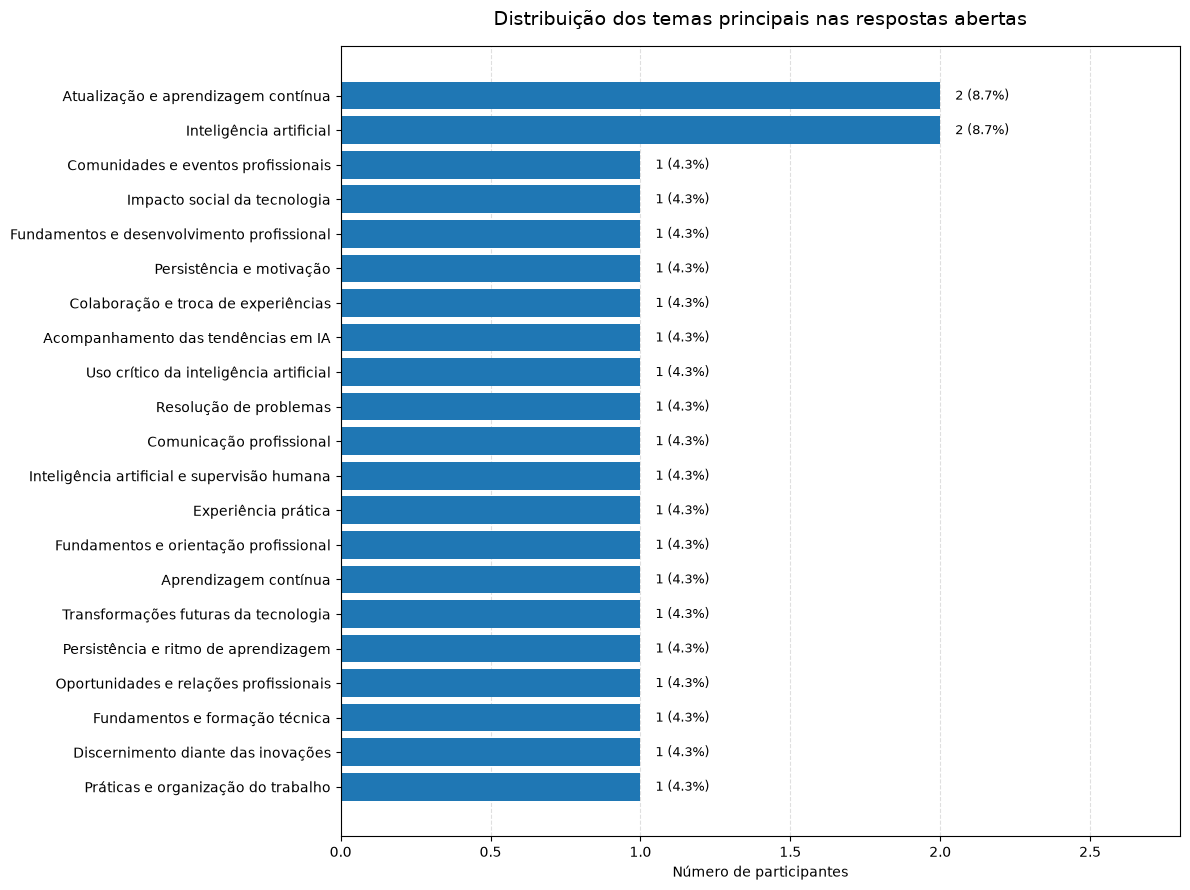

In [ ]:
# ============================================================
# 04.4 — VISUALIZAÇÃO DA FREQUÊNCIA DOS TEMAS PRINCIPAIS
# ============================================================

import matplotlib.pyplot as plt

dados_grafico = frequencia_temas.sort_values("Participantes", ascending=True)

fig, ax = plt.subplots(figsize=(12, 9))

barras = ax.barh(dados_grafico["Tema principal"], dados_grafico["Participantes"])

ax.set_title(
    "Distribuição dos temas principais nas respostas abertas", fontsize=14, pad=15
)

ax.set_xlabel("Número de participantes")
ax.set_ylabel("")

ax.set_xlim(0, dados_grafico["Participantes"].max() + 0.8)

for barra, percentual in zip(barras, dados_grafico["Percentual"]):
    valor = barra.get_width()

    ax.text(
        valor + 0.05,
        barra.get_y() + barra.get_height() / 2,
        f"{int(valor)} ({percentual:.1f}%)",
        va="center",
        fontsize=9,
    )

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Leitura analítica

Foram analisadas 23 respostas abertas, às quais foram atribuídos 21 rótulos de tema principal. A maioria dos rótulos apareceu uma única vez, e apenas "Atualização e aprendizagem contínua" e "Inteligência artificial" se repetiram, com duas respostas cada (8,7%).

Essa baixa repetição, porém, vem em parte da forma como os rótulos foram nomeados. Alguns assuntos aparecem sob formulações próximas:

- **Inteligência artificial:** cinco respostas (21,7%), distribuídas em quatro rótulos ("Inteligência artificial", "Inteligência artificial e supervisão humana", "Uso crítico da inteligência artificial" e "Acompanhamento das tendências em IA").
- **Aprendizagem contínua:** três respostas (13,0%), em dois rótulos ("Atualização e aprendizagem contínua" e "Aprendizagem contínua").
- **Fundamentos:** três respostas (13,0%), em três rótulos ("Fundamentos e formação técnica", "Fundamentos e orientação profissional" e "Fundamentos e desenvolvimento profissional").
- **Persistência:** duas respostas (8,7%), em dois rótulos ("Persistência e ritmo de aprendizagem" e "Persistência e motivação").

Os demais temas, como comunicação, colaboração, experiência prática, resolução de problemas, comunidades e eventos, impacto social e discernimento diante das inovações, aparecem uma vez cada.

As manifestações abrangem desde fundamentos técnicos e experiência prática até o uso crítico da inteligência artificial, a comunicação, a colaboração e a atenção às transformações do mercado.

**Nota metodológica:** a análise considera 23 respostas classificadas; uma resposta foi excluída por não apresentar conteúdo relacionado à pergunta. Os temas principais foram atribuídos por análise qualitativa e mantidos como nomeados na tabela. A aproximação entre rótulos semelhantes, indicada acima, é uma leitura posterior que não altera a codificação original, e os percentuais referem-se às 23 respostas analisadas, não aos 54 participantes.

### 04.5 — Temas secundários das respostas abertas

Esta etapa complementa a análise dos temas principais, identificando outros assuntos, competências e percepções presentes nas respostas dos participantes. O objetivo é ampliar a compreensão das recomendações compartilhadas e da diversidade de perspectivas registradas nos relatos.

In [ ]:
# ============================================================
# 04.5 — FREQUÊNCIA DOS TEMAS SECUNDÁRIOS
# ============================================================

temas_secundarios = (
    df_temas["Temas secundários"].dropna().str.split(";").explode().str.strip()
)

temas_secundarios = temas_secundarios[temas_secundarios.ne("")]

# Normalização para evitar duplicidade por diferença de caixa
df_secundarios = pd.DataFrame(
    {"Tema original": temas_secundarios, "Chave": temas_secundarios.str.casefold()}
)

# Agrupamento por grafia normalizada
frequencia_secundarios = (
    df_secundarios.groupby("Chave")
    .agg(
        **{
            "Tema secundário": ("Tema original", "first"),
            "Participantes": ("Tema original", "size"),
        }
    )
    .reset_index(drop=True)
    .sort_values(["Participantes", "Tema secundário"], ascending=[False, True])
    .reset_index(drop=True)
)

frequencia_secundarios["Percentual"] = (
    frequencia_secundarios["Participantes"] / len(df_temas) * 100
).round(1)

print("FREQUÊNCIA DOS TEMAS SECUNDÁRIOS")
print("=" * 55)
print(f"Respostas consideradas: {len(df_temas)}")
print(f"Menções registradas: {len(temas_secundarios)}")
print(f"Temas distintos após normalização: {len(frequencia_secundarios)}")

display(frequencia_secundarios)

FREQUÊNCIA DOS TEMAS SECUNDÁRIOS
Respostas consideradas: 23
Menções registradas: 59
Temas distintos após normalização: 58


,Tema secundário,Participantes,Percentual
0,Conhecimento de ferramentas,2,8.7
1,Abertura à mudança,1,4.3
2,Aplicação de ferramentas,1,4.3
3,Aprendizagem contínua,1,4.3
4,Aprendizagem direcionada,1,4.3
5,Aprendizagem pela prática,1,4.3
6,Aprendizagem progressiva,1,4.3
7,Autonomia,1,4.3
8,Autonomia intelectual,1,4.3
9,Clareza,1,4.3


### 04.6 — Aproximações temáticas dos relatos

Esta etapa reúne os temas secundários por aproximação de sentido, buscando identificar dimensões comuns entre as recomendações apresentadas pelos participantes, sem eliminar as particularidades de cada relato.

In [ ]:
import pandas as pd
from IPython.display import display

# ============================================================
# 04.6 — APROXIMAÇÕES TEMÁTICAS DOS RELATOS
# ============================================================

# Mapeamento explícito dos temas secundários
agrupamentos = {
    "Fundamentos e conhecimentos técnicos": [
        "Aplicação de ferramentas",
        "Conhecimento de ferramentas",
        "Domínio tecnológico",
        "Fundamentos perenes",
        "Lógica de programação",
        "Consolidação de fundamentos",
        "Desempenho",
        "Documentação técnica",
        "Identificação de problemas",
        "Qualidade",
        "Refatoração",
        "Resolução de problemas",
        "Revisão de código",
    ],
    "Aprendizagem e desenvolvimento profissional": [
        "Aprendizagem contínua",
        "Aprendizagem direcionada",
        "Aprendizagem gradual",
        "Aprendizagem progressiva",
        "Aprendizagem",
        "Atualização profissional",
        "Paciência",
        "Foco",
        "Resiliência",
        "Continuidade",
        "Curiosidade",
        "Especialização",
        "Aprendizagem pela prática",
    ],
    "Comunicação e colaboração": [
        "Clareza",
        "Adequação ao público",
        "Alinhamento de expectativas",
        "Colaboração",
        "Compartilhamento de conhecimentos",
        "Diversidade de soluções",
        "Troca de experiências",
        "Geração de ideias",
    ],
    "Mercado e relações profissionais": [
        "Informação",
        "LinkedIn",
        "Compreensão das necessidades do mercado",
        "Networking",
        "Posicionamento profissional",
        "Relevância profissional",
        "Troca com profissionais experientes",
    ],
    "Autonomia e pensamento crítico": [
        "Abertura à mudança",
        "Autonomia",
        "Autonomia intelectual",
        "Avaliação crítica de tendências",
        "Questionamento",
        "Validação",
    ],
    "Inteligência artificial e transformações tecnológicas": [
        "Inteligência artificial",
        "Entidades inteligentes",
        "Incorporação da IA à rotina",
        "Inovação",
        "Transformações do mercado",
    ],
    "Experiência prática e aplicação": [
        "Produtividade",
        "Projetos práticos",
        "Portfólio",
    ],
    "Impacto e responsabilidade social": [
        "Interesse coletivo",
        "Soluções para a população",
        "Responsabilidade social",
    ],
}

# Criação do mapa de classificação
mapa_temas = {
    tema.strip().casefold(): grupo
    for grupo, temas in agrupamentos.items()
    for tema in temas
}

# Cópia da tabela original
df_aproximacoes = frequencia_secundarios.copy()

# Aplicação dos agrupamentos
df_aproximacoes["Aproximação temática"] = df_aproximacoes["Tema secundário"].apply(
    lambda tema: mapa_temas.get(str(tema).strip().casefold(), "Revisão necessária")
)

# ============================================================
# RESULTADO 1 — FREQUÊNCIA DAS APROXIMAÇÕES
# ============================================================

frequencia_aproximacoes = (
    df_aproximacoes.groupby("Aproximação temática", as_index=False)
    .agg(Menções=("Participantes", "sum"), Temas_originais=("Tema secundário", "count"))
    .sort_values("Menções", ascending=False)
    .reset_index(drop=True)
)

# Percentual sobre o total de menções
total_mencoes = frequencia_aproximacoes["Menções"].sum()

frequencia_aproximacoes["Percentual"] = (
    frequencia_aproximacoes["Menções"] / total_mencoes * 100
).round(1)

print("FREQUÊNCIA DAS APROXIMAÇÕES TEMÁTICAS")
print("=" * 60)
print(f"Temas secundários: {len(df_aproximacoes)}")
print(f"Menções registradas: {total_mencoes}")

display(frequencia_aproximacoes)

# ============================================================
# RESULTADO 2 — RASTREABILIDADE DOS TEMAS
# ============================================================

print("TEMAS ORIGINAIS POR APROXIMAÇÃO TEMÁTICA")
print("=" * 60)

display(
    df_aproximacoes[["Tema secundário", "Participantes", "Aproximação temática"]]
    .sort_values(["Aproximação temática", "Tema secundário"])
    .reset_index(drop=True)
)

# ============================================================
# RESULTADO 3 — CONFERÊNCIA DA CLASSIFICAÇÃO
# ============================================================

temas_revisar = df_aproximacoes[
    df_aproximacoes["Aproximação temática"] == "Revisão necessária"
]

print("CONFERÊNCIA DA CLASSIFICAÇÃO")
print("=" * 60)
print(f"Temas identificados: {len(df_aproximacoes)}")
print(f"Temas classificados: {len(df_aproximacoes) - len(temas_revisar)}")
print(f"Temas pendentes: {len(temas_revisar)}")

if not temas_revisar.empty:
    display(temas_revisar)
else:
    print("Todos os temas receberam uma aproximação temática.")

# Conferência da soma das menções
print(
    f"\nTotal de menções na tabela original: "
    f"{frequencia_secundarios['Participantes'].sum()}"
)

print(f"Total de menções após agrupamento: {total_mencoes}")

FREQUÊNCIA DAS APROXIMAÇÕES TEMÁTICAS
Temas secundários: 58
Menções registradas: 59


,Aproximação temática,Menções,Temas_originais,Percentual
0,Fundamentos e conhecimentos técnicos,14,13,23.7
1,Aprendizagem e desenvolvimento profissional,13,13,22.0
2,Comunicação e colaboração,8,8,13.6
3,Mercado e relações profissionais,7,7,11.9
4,Autonomia e pensamento crítico,6,6,10.2
5,Inteligência artificial e transformações tecnológicas,5,5,8.5
6,Experiência prática e aplicação,3,3,5.1
7,Impacto e responsabilidade social,3,3,5.1


TEMAS ORIGINAIS POR APROXIMAÇÃO TEMÁTICA


,Tema secundário,Participantes,Aproximação temática
0,Aprendizagem contínua,1,Aprendizagem e desenvolvimento profissional
1,Aprendizagem direcionada,1,Aprendizagem e desenvolvimento profissional
2,Aprendizagem pela prática,1,Aprendizagem e desenvolvimento profissional
3,Aprendizagem progressiva,1,Aprendizagem e desenvolvimento profissional
4,Paciência,1,Aprendizagem e desenvolvimento profissional
5,Resiliência,1,Aprendizagem e desenvolvimento profissional
6,aprendizagem,1,Aprendizagem e desenvolvimento profissional
7,aprendizagem gradual,1,Aprendizagem e desenvolvimento profissional
8,atualização profissional,1,Aprendizagem e desenvolvimento profissional
9,continuidade,1,Aprendizagem e desenvolvimento profissional


CONFERÊNCIA DA CLASSIFICAÇÃO
Temas identificados: 58
Temas classificados: 58
Temas pendentes: 0
Todos os temas receberam uma aproximação temática.

Total de menções na tabela original: 59
Total de menções após agrupamento: 59


### Leitura analítica

O agrupamento das 59 menções em oito aproximações temáticas permite observar quais dimensões aparecem com maior frequência nas recomendações apresentadas pelos participantes.

A aproximação **Fundamentos e conhecimentos técnicos** apresenta a maior frequência, com 14 menções (23,7%). O resultado evidencia a valorização da construção de uma base técnica, reunindo referências a ferramentas, lógica de programação, domínio tecnológico, documentação, qualidade e resolução de problemas.

Em seguida, **Aprendizagem e desenvolvimento profissional** reúne 13 menções (22,0%). Os relatos agrupados nessa dimensão destacam aprendizagem contínua, atualização profissional, especialização, curiosidade e desenvolvimento progressivo. A proximidade entre essas duas aproximações indica que o preparo para atuar na área é associado tanto à aquisição de conhecimentos quanto à disposição para continuar aprendendo.

Juntas, essas duas categorias concentram 45,7% das menções, evidenciando a predominância de recomendações relacionadas à formação técnica e ao desenvolvimento profissional.

As demais aproximações ampliam o conjunto de orientações:

- **Comunicação e colaboração** (13,6%) reúne referências à troca de experiências, ao compartilhamento de conhecimentos, à clareza e à colaboração.
- **Mercado e relações profissionais** (11,9%) contempla networking, posicionamento profissional, compreensão do mercado e contato com profissionais experientes.
- **Autonomia e pensamento crítico** (10,2%) reúne autonomia, abertura à mudança, questionamento, validação e avaliação crítica de tendências.
- **Inteligência artificial e transformações tecnológicas** (8,5%) agrupa referências à inteligência artificial, à incorporação dessas ferramentas à rotina e às transformações do mercado.
- **Experiência prática e aplicação** (5,1%) contempla projetos práticos e construção de portfólio.
- **Impacto e responsabilidade social** (5,1%) reúne referências ao interesse coletivo, à responsabilidade social e à busca de soluções para a população.

A distribuição mostra que as recomendações não se restringem ao domínio técnico. Também aparecem dimensões relacionadas à capacidade de trabalhar com outras pessoas, desenvolver autonomia, construir relações profissionais, aplicar conhecimentos e compreender os impactos da tecnologia.

**Nota metodológica:** as aproximações temáticas foram construídas a partir dos 58 temas secundários distintos identificados nos relatos. Como um dos temas apareceu em duas respostas, o conjunto totaliza 59 menções, provenientes de 23 participantes. Os percentuais representam a distribuição dessas menções entre as aproximações, e não a proporção dos 54 respondentes da pesquisa.

# 05 — Síntese analítica — Eixo 4: Olhando para frente

A análise deste eixo investigou o que os participantes consideram importante para quem está começando na área de tecnologia e quais alertas, tendências e recomendações desejam compartilhar a partir de suas experiências profissionais. Os resultados articulam as alternativas selecionadas no questionário, as combinações de recomendações e as manifestações registradas nas respostas abertas.

## Recomendações selecionadas

As recomendações mais frequentes, apresentadas também no Eixo 3, foram **aprendizagem contínua**, indicada por 38 participantes (70,4%), **busca por experiência prática**, por 30 (55,6%), e **desenvolvimento de conhecimento técnico**, por 27 (50,0%). As habilidades comportamentais foram indicadas por 25 participantes (46,3%). Como a questão permitia até três escolhas, esses percentuais mostram quais recomendações foram priorizadas entre as alternativas, e não a ausência das demais.

Foram identificadas 35 combinações distintas de recomendações, sem que uma única configuração predominasse. As dez combinações mais frequentes reuniram 29 participantes (53,7%), e 25 participantes (46,3%) apresentaram combinações que não se repetiram. Os participantes, portanto, não apontam um único caminho de preparação para quem está começando.

## Respostas abertas

A pergunta aberta foi respondida por 24 dos 54 participantes. Uma resposta foi excluída por não apresentar conteúdo relacionado à pergunta, e 23 foram analisadas. Como a pergunta era opcional, as respostas em branco não indicam ausência de opinião.

Na classificação por tema principal, a maioria dos rótulos apareceu uma única vez, o que indica relatos bastante particulares. Alguns assuntos, porém, reaparecem sob rótulos diferentes. A inteligência artificial é o tema principal de cinco das 23 respostas, com formulações distintas, como uso crítico, supervisão humana e acompanhamento das tendências. A aprendizagem contínua e a atualização aparecem em mais de uma resposta com nomes próximos.

Para compreender o conjunto, os temas secundários, que resultaram em 59 menções a partir de 23 participantes, foram reunidos em oito aproximações temáticas. As duas maiores foram **Fundamentos e conhecimentos técnicos**, com 14 menções (23,7%), e **Aprendizagem e desenvolvimento profissional**, com 13 (22,0%), que juntas somam 45,7% das menções. Em seguida aparecem Comunicação e colaboração (13,6%), Mercado e relações profissionais (11,9%) e Autonomia e pensamento crítico (10,2%). Inteligência artificial e transformações tecnológicas (8,5%), Experiência prática e aplicação (5,1%) e Impacto e responsabilidade social (5,1%) completam o conjunto.

## Leitura conjunta

Há convergência entre as duas partes do eixo. A aprendizagem contínua e o conhecimento técnico, que lideram as alternativas selecionadas, também estão entre as duas maiores aproximações das respostas abertas. As respostas abertas também trazem dimensões que as alternativas do formulário não contemplavam diretamente: autonomia e pensamento crítico, responsabilidade social e, de modo mais explícito, a inteligência artificial. Comunicação e colaboração, e mercado e relações profissionais, podem ser aproximados de habilidades comportamentais, rede de contatos e acompanhamento de tendências, mas essa correspondência é uma leitura interpretativa, e as duas perguntas não foram cruzadas entre si.

A inteligência artificial não integrava as alternativas da pergunta fechada. Sua presença vem exclusivamente dos relatos espontâneos, nos quais aparece como tema principal em cinco respostas e como uma das aproximações temáticas. As manifestações indicam que as transformações tecnológicas fazem parte das preocupações de parte dos participantes, mas não permitem dimensionar a intensidade ou a forma de adoção dessas tecnologias pelo conjunto da amostra.

Em conjunto, os resultados apontam para uma visão de desenvolvimento profissional que articula conhecimento técnico, aprendizagem permanente, experiência prática e competências relacionais e críticas. As recomendações não configuram uma trajetória única ou uma sequência obrigatória de etapas.

**Limites da análise:** os resultados representam as percepções dos 54 participantes da pesquisa. A questão de recomendações permitia até três seleções por pessoa, e as respostas abertas foram analisadas a partir de 23 manifestações voluntárias. Na aproximação temática, as 59 menções correspondem a 58 temas secundários distintos, pois um tema apareceu em duas respostas; os percentuais desse agrupamento representam a distribuição das menções entre as aproximações, e não a proporção dos participantes. Os resultados são exploratórios e não permitem estabelecer relações causais ou generalizações para o conjunto dos profissionais de tecnologia.

# 06 — Encerramento do Eixo 4 — Olhando para frente

### Delimitação do eixo

A análise deste eixo esteve concentrada nas recomendações que os participantes consideram importantes para quem está começando na área de tecnologia e nas percepções, alertas e tendências compartilhados a partir de suas experiências profissionais.

Foram examinadas as alternativas selecionadas pelos participantes, as combinações de recomendações e as manifestações espontâneas registradas nas respostas abertas. A análise temática dessas manifestações permitiu organizar os relatos em aproximações relacionadas à formação e ao desenvolvimento profissional, à comunicação e colaboração, às relações de mercado, à autonomia e ao pensamento crítico, às transformações tecnológicas, à experiência prática e à responsabilidade social.

Os resultados expressam as percepções dos participantes da amostra investigada. As respostas abertas representam manifestações voluntárias e, portanto, não correspondem necessariamente ao conjunto dos 54 respondentes. As aproximações temáticas organizam os conteúdos identificados, sem eliminar a diversidade de sentidos presentes nos relatos.

### Continuidade da investigação

Com a conclusão dos quatro eixos principais, a pesquisa encerra a análise das trajetórias, experiências profissionais e perspectivas dos participantes.

A investigação terá continuidade em uma dimensão complementar, organizada em um notebook específico:

- **Eixo complementar — Uso de Inteligência Artificial:** análise da frequência e das finalidades de utilização de ferramentas de IA generativa no trabalho com dados, considerando as 18 respostas registradas para essas perguntas.

Essa análise será conduzida separadamente dos quatro eixos principais, respeitando o universo específico de respondentes e ampliando a compreensão sobre a incorporação da inteligência artificial às práticas profissionais na área de tecnologia.